# NB\_C02: Clinical, Cognitive, and Psychosocial Profile

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB_C02_Clinical_Cognitive_Data.ipynb)

**Capstone Notebook Series** -- Glioma Brain Digital Twin Project  
**Workshop:** Mathematical Challenges in Brain Mechanics ([CAS 2025/2026](https://cas-nor.no/project/mathematical-challenges-brain-mechanics)), 9-11 March 2026, Hotel Finse 1222 [[link](https://cas-nor.no/events/mathematical-challenges-brain-mechanics-workshop)]  
**Patient:** sub-PAT16 (anaplastic astrocytoma WHO II--III, fronto-temporal) from the OpenNeuro repository [[preop](https://openneuro.org/datasets/ds001226/versions/5.0.0)] [[postop](https://openneuro.org/datasets/ds002080/versions/4.0.0)]<br>
**Date:** 7 March 2026 <br>
**Creator:** Arvid Lundervold w/ Cursor 2.6.12 and Opus 4.6

---

## Objectives

- Understand the CANTAB cognitive battery and what each test measures
- Map cognitive domains to specific brain regions (DK68 parcellation)
- Analyse pre-operative vs post-operative cognitive change
- Interpret psychosocial measures (STAI, PSWQ, ERQ, UCLA) and their interaction with cognition
- Appreciate why psychosocial context matters for interpreting cognitive outcomes

**Prerequisites:** [NB\_C01](NB_C01_Digital_Twin_Concept_and_Data.ipynb)  
**Next:** [NB\_C03](NB_C03_Structural_MRI_Segmentation.ipynb) (structural MRI)

---
## 1. The CANTAB Battery: Cognitive Neuroscience Background

The **CANTAB** (Cambridge Neuropsychological Test Automated Battery) is a
computerised cognitive assessment system developed at the University of
Cambridge. Unlike paper-and-pencil tests, CANTAB provides:

- **Standardised**, language-independent visual stimuli
- **Millisecond-precision** reaction time measurement
- **Normative data** stratified by age, sex, and education
- **Domain-specific** tests that map onto known brain circuits

### Tests administered to PAT16

| Test | Full name | Cognitive domain | Key brain regions | Key metric | Direction |
|------|-----------|-----------------|-------------------|------------|----------|
| **MOT** | Motor Screening | Basic motor function | Primary motor cortex (precentral), paracentral lobule | Latency (ms) | Lower = better |
| **RTI** | Reaction Time | Processing speed | Precentral gyrus, superior frontal, basal ganglia-thalamocortical circuit | Simple RT (ms) | Lower = better |
| **RVP** | Rapid Visual Processing | Sustained attention | Caudal middle frontal (dorsolateral PFC), inferior parietal (attention network) | A' (signal detection) | Higher = better |
| **SOC** | Stockings of Cambridge | Executive function / planning | Superior frontal (dorsolateral PFC), pars opercularis (Broca's area) | Problems solved in min moves | Higher = better |
| **SSP** | Spatial Span | Visuospatial working memory | Caudal middle frontal, superior parietal, precuneus | Span length | Higher = better |

### The Cognitive Neuroscience of CANTAB

Each CANTAB test engages specific neural circuits that are well-characterised
from lesion studies and functional neuroimaging:

**MOT / RTI (Motor and Processing Speed):**
Simple reaction time depends on the integrity of the basal ganglia-
thalamocortical loop. The signal flows: visual cortex $\to$ superior
colliculus $\to$ thalamus $\to$ motor cortex $\to$ corticospinal tract.
Damage anywhere along this pathway increases latency. In PAT16, the
fronto-temporal tumour is adjacent to the motor strip, potentially
affecting both the corticospinal tract and supplementary motor area.

**RVP (Sustained Attention):**
Sustained attention requires tonic activation of the right frontoparietal
network. The dorsolateral prefrontal cortex (DLPFC) maintains the task
set, while the inferior parietal lobule monitors the stimulus stream.
The A' metric from signal detection theory separates sensitivity from
response bias: A' $= 0.5 + \frac{(H - F)(1 + H - F)}{4H(1-F)}$ where
$H$ is hit rate and $F$ is false alarm rate.

**SOC (Executive Function / Planning):**
Based on the Tower of London task (Shallice, 1982). Requires the DLPFC
for planning, the caudate nucleus for action selection, and the anterior
cingulate for error monitoring. Patients with frontal lobe lesions
characteristically solve fewer problems in the minimum number of moves
(Owen et al., 1990; Robbins et al., 1998).

**SSP (Visuospatial Working Memory):**
A computerised version of the Corsi block-tapping task. Engages the
visuospatial sketchpad (Baddeley's model), subserved by the posterior
parietal cortex and right-lateralised prefrontal regions. Span length
typically ranges from 4--9 in healthy adults.

In [13]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import pandas as pd
import json
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Colab / local environment setup ─────────────────────────────────────────
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             str(REPO_ROOT)],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r {REPO_ROOT}/environment/requirements-colab.txt
    if not (REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'sub-PAT16').exists():
        !python {REPO_ROOT}/data/download_data.py --capstone
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

sys.path.insert(0, str(REPO_ROOT))

BIDS_ROOT  = REPO_ROOT / 'data' / 'BIDS_preop_postop'
FIG_DIR    = Path('figures') / 'capstone'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300,
                     'font.size': 10, 'axes.titlesize': 12,
                     'figure.facecolor': 'white'})

sessions_tsv  = BIDS_ROOT / 'sub-PAT16' / 'sub-PAT16_sessions.tsv'
sessions_json = BIDS_ROOT / 'sub-PAT16' / 'sub-PAT16_sessions.json'

df_ses = pd.read_csv(sessions_tsv, sep='\t', index_col='session_id')
with open(sessions_json) as f:
    meta_ses = json.load(f)

print(f'Sessions loaded: {list(df_ses.index)}')
print(f'Total variables: {len(df_ses.columns)}')

Sessions loaded: ['ses-preop', 'ses-postop']
Total variables: 47


---
## 2. Domain-to-Parcel Mapping

Each CANTAB test engages specific cortical regions that can be mapped onto
the Desikan-Killiany 68-region parcellation (DK68). This mapping enables
us to connect cognitive outcomes to structural and functional connectivity
changes in the digital twin (NB\_C07, NB\_C08).

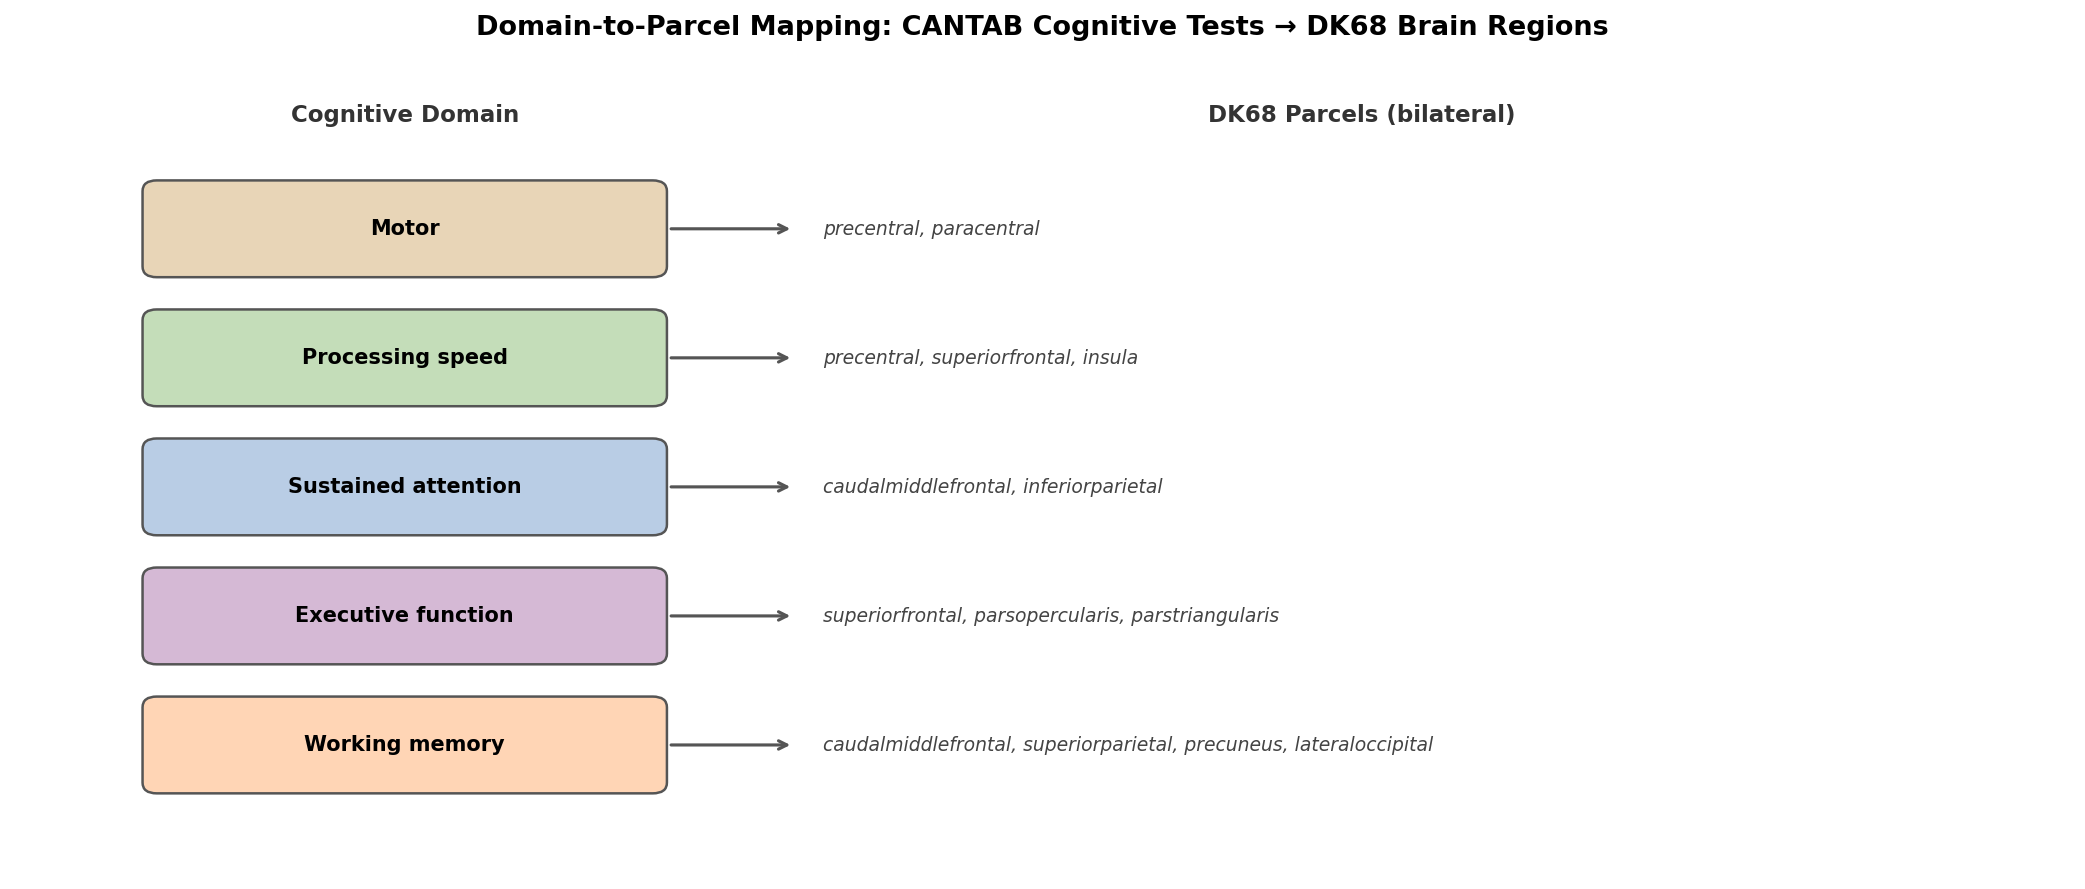

In [14]:
domain_to_parcels = {
    'Motor':               ['precentral', 'paracentral'],
    'Processing speed':    ['precentral', 'superiorfrontal', 'insula'],
    'Sustained attention': ['caudalmiddlefrontal', 'inferiorparietal'],
    'Executive function':  ['superiorfrontal', 'parsopercularis', 'parstriangularis'],
    'Working memory':      ['caudalmiddlefrontal', 'superiorparietal',
                            'precuneus', 'lateraloccipital'],
}

fig, ax = plt.subplots(figsize=(14, 6))
ax.axis('off')
fig.suptitle('Domain-to-Parcel Mapping: CANTAB Cognitive Tests \u2192 DK68 Brain Regions',
             fontsize=13, fontweight='bold')

domain_colors = {
    'Motor':               '#E8D5B7',
    'Processing speed':    '#C4DDB9',
    'Sustained attention': '#B9CDE5',
    'Executive function':  '#D5B9D5',
    'Working memory':      '#FFD5B5',
}

y_start = 5.0
for i, (domain, parcels) in enumerate(domain_to_parcels.items()):
    y = y_start - i * 1.2
    color = domain_colors[domain]
    rect = FancyBboxPatch((0.5, y - 0.35), 3.5, 0.7,
                          boxstyle='round,pad=0.1', facecolor=color,
                          edgecolor='#555', lw=1.2)
    ax.add_patch(rect)
    ax.text(2.25, y, domain, ha='center', va='center',
            fontsize=10, fontweight='bold')
    ax.annotate('', xy=(5.0, y), xytext=(4.1, y),
                arrowprops=dict(arrowstyle='->', lw=1.5, color='#555'))
    parcel_text = ', '.join(parcels)
    ax.text(5.2, y, parcel_text, ha='left', va='center',
            fontsize=9, fontstyle='italic', color='#444')

ax.set_xlim(-0.5, 14)
ax.set_ylim(-1, 6.5)
ax.text(2.25, 6.0, 'Cognitive Domain', ha='center', fontsize=11,
        fontweight='bold', color='#333')
ax.text(9.0, 6.0, 'DK68 Parcels (bilateral)', ha='center', fontsize=11,
        fontweight='bold', color='#333')

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC02_01_domain_parcel_mapping.png', bbox_inches='tight')
plt.show()

---
## 3. CANTAB Results: Pre-op vs Post-op

We now load the CANTAB metrics from the sessions file and compute the
pre-to-post change for each test. For latency/RT metrics, a *decrease*
indicates improvement; for accuracy/span metrics, an *increase* indicates
improvement.

In [15]:
cantab_metrics = {
    'MOT latency (ms)':     ('mot_latency_mean',  'Motor',              'lower_better'),
    'RTI simple RT (ms)':   ('rti_simple_rt_mean', 'Processing speed',  'lower_better'),
    'RTI 5-choice RT (ms)': ('rti_five_rt',        'Attention / speed', 'lower_better'),
    'RVP A\' (signal det)': ('rvp_a',              'Sustained attention','higher_better'),
    'SOC min-move solved':  ('soc_prob_min_moves', 'Executive function','higher_better'),
    'SSP span length':      ('ssp_span_length',    'Working memory',    'higher_better'),
}

cog_results = []
for label, (col, domain, direction) in cantab_metrics.items():
    if col not in df_ses.columns:
        continue
    try:
        pre  = float(df_ses.loc['ses-preop', col])
        post = float(df_ses.loc['ses-postop', col])
        delta = post - pre
        pct = 100 * delta / abs(pre) if pre != 0 else 0
        if direction == 'lower_better':
            improved = delta < 0
        else:
            improved = delta > 0
        cog_results.append({'Metric': label, 'Domain': domain,
                           'Pre-op': pre, 'Post-op': post,
                           'Delta': delta, '%Delta': pct,
                           'Improved': improved, 'Direction': direction})
    except (ValueError, KeyError):
        pass

df_cog = pd.DataFrame(cog_results)
print('CANTAB cognitive change (pre \u2192 post):')
print(df_cog[['Metric', 'Domain', 'Pre-op', 'Post-op', '%Delta', 'Improved']].to_string(index=False))

CANTAB cognitive change (pre → post):
              Metric              Domain  Pre-op    Post-op     %Delta  Improved
    MOT latency (ms)               Motor  817.80 844.500000   3.264857     False
  RTI simple RT (ms)    Processing speed  403.78 345.555556 -14.419844      True
RTI 5-choice RT (ms)   Attention / speed  361.50 327.000000  -9.543568      True
 RVP A' (signal det) Sustained attention    0.95   0.952355   0.247922      True
 SOC min-move solved  Executive function    8.00   8.000000   0.000000     False
     SSP span length      Working memory    6.00   7.000000  16.666667      True


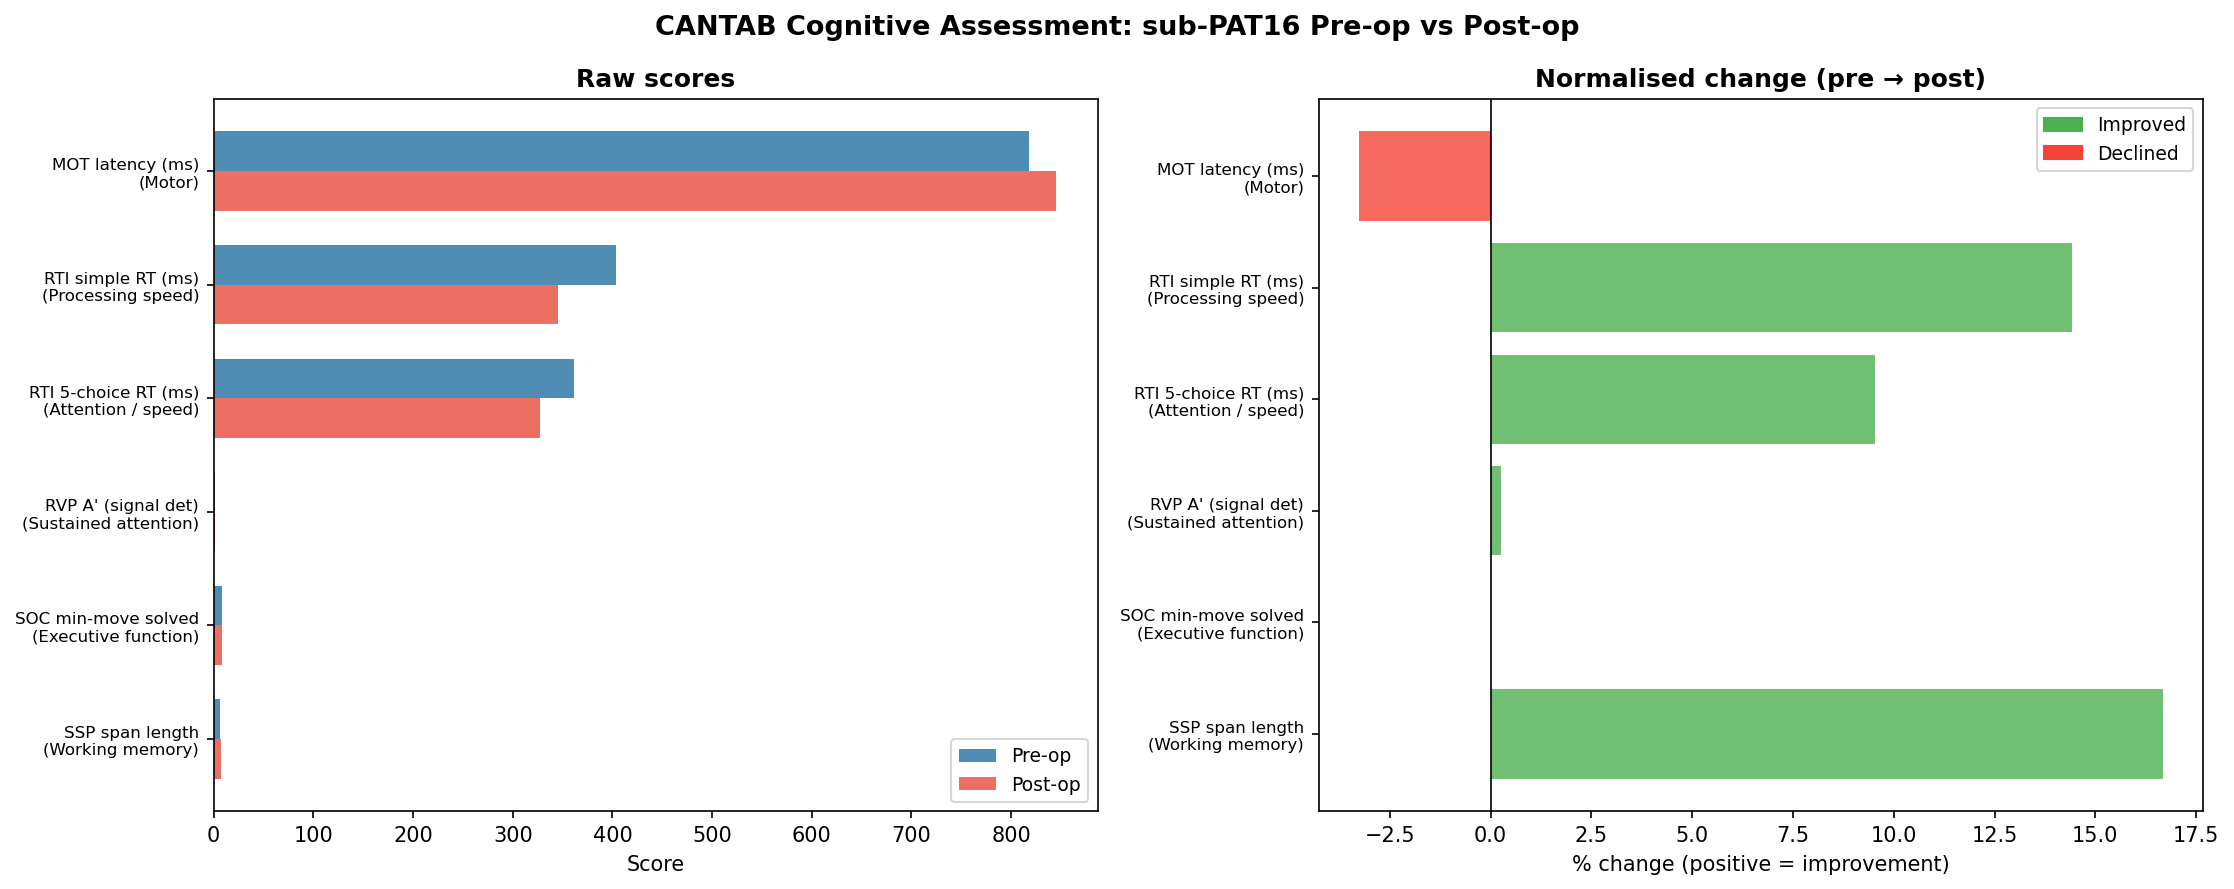

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('CANTAB Cognitive Assessment: sub-PAT16 Pre-op vs Post-op',
             fontsize=13, fontweight='bold')

# Panel 1: Raw scores
ax = axes[0]
if len(df_cog) > 0:
    y_pos = range(len(df_cog))
    bar_h = 0.35
    ax.barh([y - bar_h/2 for y in y_pos], df_cog['Pre-op'], bar_h,
            label='Pre-op', color='#2471A3', alpha=0.8)
    ax.barh([y + bar_h/2 for y in y_pos], df_cog['Post-op'], bar_h,
            label='Post-op', color='#E74C3C', alpha=0.8)
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels([f"{r['Metric']}\n({r['Domain']})" for _, r in df_cog.iterrows()],
                       fontsize=8)
    ax.set_xlabel('Score')
    ax.set_title('Raw scores', fontweight='bold')
    ax.legend(fontsize=9, loc='lower right')
    ax.invert_yaxis()

# Panel 2: Normalised change
ax = axes[1]
if len(df_cog) > 0:
    pct_display = []
    for _, r in df_cog.iterrows():
        v = r['%Delta']
        if r['Direction'] == 'lower_better':
            v = -v
        pct_display.append(v)
    colors_cog = ['#4CAF50' if v > 0 else '#F44336' for v in pct_display]
    y_pos = range(len(df_cog))
    ax.barh(y_pos, pct_display, color=colors_cog, alpha=0.8)
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels([f"{r['Metric']}\n({r['Domain']})" for _, r in df_cog.iterrows()],
                       fontsize=8)
    ax.axvline(0, color='k', linewidth=0.8)
    ax.set_xlabel('% change (positive = improvement)')
    ax.set_title('Normalised change (pre \u2192 post)', fontweight='bold')
    ax.invert_yaxis()
    ax.legend(handles=[
        mpatches.Patch(color='#4CAF50', label='Improved'),
        mpatches.Patch(color='#F44336', label='Declined'),
    ], fontsize=9)

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC02_02_cantab_prepost.png', bbox_inches='tight')
plt.show()

---
## 4. Psychosocial Measures

Cognitive outcomes do not occur in a vacuum. Anxiety, worry, emotion
regulation, and social connectedness all modulate cognitive performance.
This is well-established in cognitive psychology:

- **Eysenck's Attentional Control Theory** (2007): anxiety impairs the
  efficiency of the central executive and attentional systems, particularly
  shifting and inhibition functions. High anxiety consumes working memory
  capacity through intrusive worry.

- **Emotion Regulation** (Gross, 2015): cognitive reappraisal (reframing
  a situation) is an adaptive strategy that reduces negative affect without
  cognitive cost, while suppression (hiding emotional expression) is
  maladaptive and impairs memory and executive function.

### Measures

| Measure | What it assesses | Range | Clinical threshold |
|---------|-----------------|-------|-------------------|
| **STAI** (State-Trait Anxiety Inventory) | State and trait anxiety | 20--80 | >40 = clinically significant |
| **PSWQ** (Penn State Worry Questionnaire) | Pathological worry | 16--80 | >62 = high worry |
| **ERQ Reappraisal** | Cognitive reappraisal use | 6--42 | Higher = more adaptive |
| **ERQ Suppression** | Expressive suppression use | 4--28 | Higher = more maladaptive |
| **UCLA Loneliness** | Perceived social isolation | 20--80 | >40 = moderate loneliness |

In [17]:
psychosocial_metrics = {
    'STAI (anxiety)':       ('stai',              'lower_better'),
    'PSWQ (worry)':         ('pswq',              'lower_better'),
    'ERQ reappraisal':      ('erq_reappraisal',   'higher_better'),
    'ERQ suppression':      ('erq_suppression',   'neutral'),
    'UCLA Loneliness':      ('loneliness',        'lower_better'),
}

psy_results = []
for label, (col, direction) in psychosocial_metrics.items():
    if col not in df_ses.columns:
        continue
    try:
        pre  = float(df_ses.loc['ses-preop', col])
        post = float(df_ses.loc['ses-postop', col])
        delta = post - pre
        pct = 100 * delta / abs(pre) if pre != 0 else 0
        if direction == 'lower_better':
            improved = delta < 0
        elif direction == 'higher_better':
            improved = delta > 0
        else:
            improved = None
        psy_results.append({'Metric': label, 'Pre-op': pre, 'Post-op': post,
                           'Delta': delta, '%Delta': pct, 'Improved': improved,
                           'Direction': direction})
    except (ValueError, KeyError):
        pass

df_psy = pd.DataFrame(psy_results)

emp_pre  = df_ses.loc['ses-preop', 'employment'] if 'employment' in df_ses.columns else 'N/A'
emp_post = df_ses.loc['ses-postop', 'employment'] if 'employment' in df_ses.columns else 'N/A'

print('Psychosocial change (pre \u2192 post):')
print(df_psy[['Metric', 'Pre-op', 'Post-op', 'Delta', 'Improved']].to_string(index=False))
print(f'\nEmployment: {emp_pre} \u2192 {emp_post}')

Psychosocial change (pre → post):
         Metric  Pre-op  Post-op  Delta Improved
 STAI (anxiety)    36.0     30.0   -6.0     True
   PSWQ (worry)    54.0     61.0    7.0    False
ERQ reappraisal    24.0     14.0  -10.0    False
ERQ suppression    17.0     19.0    2.0     None
UCLA Loneliness    40.0     50.0   10.0    False

Employment: Employed → Sickleave


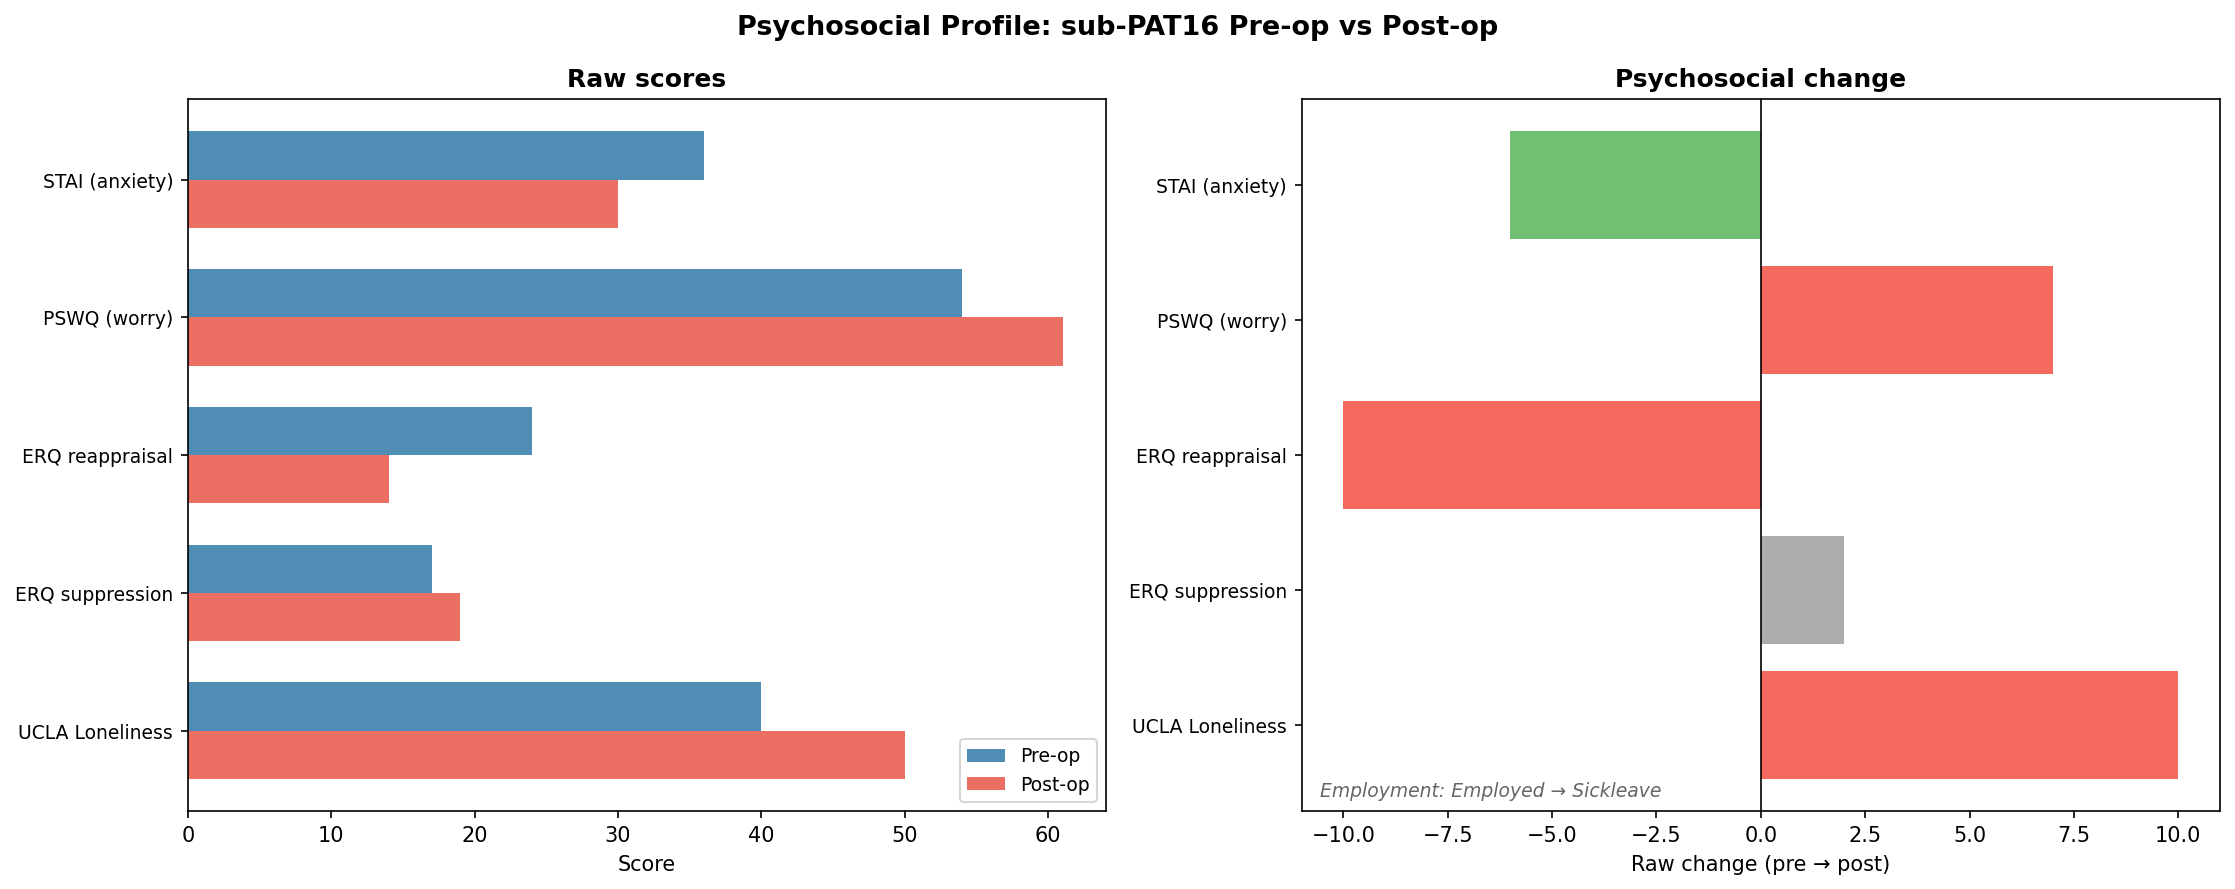

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Psychosocial Profile: sub-PAT16 Pre-op vs Post-op',
             fontsize=13, fontweight='bold')

# Panel 1: Raw scores with clinical thresholds
ax = axes[0]
if len(df_psy) > 0:
    y_pos = range(len(df_psy))
    bar_h = 0.35
    ax.barh([y - bar_h/2 for y in y_pos], df_psy['Pre-op'], bar_h,
            label='Pre-op', color='#2471A3', alpha=0.8)
    ax.barh([y + bar_h/2 for y in y_pos], df_psy['Post-op'], bar_h,
            label='Post-op', color='#E74C3C', alpha=0.8)
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels([r['Metric'] for _, r in df_psy.iterrows()], fontsize=9)
    ax.set_xlabel('Score')
    ax.set_title('Raw scores', fontweight='bold')
    ax.legend(fontsize=9, loc='lower right')
    ax.invert_yaxis()

# Panel 2: Change direction
ax = axes[1]
if len(df_psy) > 0:
    colors_psy = []
    for _, r in df_psy.iterrows():
        if r['Improved'] is True:
            colors_psy.append('#4CAF50')
        elif r['Improved'] is False:
            colors_psy.append('#F44336')
        else:
            colors_psy.append('#999999')
    y_pos = range(len(df_psy))
    ax.barh(y_pos, df_psy['Delta'], color=colors_psy, alpha=0.8)
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels([r['Metric'] for _, r in df_psy.iterrows()], fontsize=9)
    ax.axvline(0, color='k', linewidth=0.8)
    ax.set_xlabel('Raw change (pre \u2192 post)')
    ax.set_title('Psychosocial change', fontweight='bold')
    ax.invert_yaxis()
    ax.annotate(f'Employment: {emp_pre} \u2192 {emp_post}',
                xy=(0.02, 0.02), xycoords='axes fraction', fontsize=9,
                fontstyle='italic', color='#666')

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC02_03_psychosocial.png', bbox_inches='tight')
plt.show()

---
## 5. Interpreting PAT16's Profile

### Cognitive picture

The CANTAB results tell a nuanced story. The patient shows both
improvements and declines after surgery, and these need to be interpreted
in the context of which brain regions were affected by the tumour and
the surgery.

### Psychosocial context

The psychosocial measures reveal important contextual information:

- **STAI decreased** (36 $\to$ 30): state anxiety improved, possibly
  reflecting relief from diagnostic uncertainty
- **PSWQ increased** (54 $\to$ 61): worry about the future intensified,
  approaching the clinical threshold of 62
- **ERQ reappraisal dropped** (24 $\to$ 14): a substantial reduction
  in adaptive emotion regulation, which may independently impair
  executive function
- **UCLA Loneliness increased** (40 $\to$ 50): increased social
  isolation, possibly due to sick leave
- **Employment**: transitioned from employed to sick leave

The combination of increased worry, reduced coping, and social isolation
may independently affect cognitive performance -- particularly in domains
that depend on prefrontal function (attention, executive function,
working memory). This means we cannot attribute all cognitive change to
the surgery alone.

### Implications for the digital twin

The digital twin (NB\_C06--NB\_C08) predicts cognitive change from
structural disruption. Where the model predicts disruption but the
patient shows resilience, psychosocial factors (e.g., reduced anxiety)
may explain the discrepancy. Conversely, where the model predicts
preservation but the patient declines, psychosocial deterioration
(e.g., increased worry, isolation) may be the driver.

In [19]:
# Comprehensive summary table
print('=' * 80)
print('COMPREHENSIVE CLINICAL PROFILE: sub-PAT16')
print('=' * 80)
print(f'\nDiagnosis: Anaplastic astrocytoma WHO II-III, left fronto-temporal')
print(f'Employment: {emp_pre} \u2192 {emp_post}')

print('\n\u2500\u2500 CANTAB Cognitive Battery \u2500\u2500')
if len(df_cog) > 0:
    for _, r in df_cog.iterrows():
        status = '\u2713 improved' if r['Improved'] else '\u2717 declined'
        print(f"  {r['Metric']:25s}  {r['Domain']:22s}  "
              f"{r['Pre-op']:8.1f} \u2192 {r['Post-op']:8.1f}  "
              f"({r['%Delta']:+.1f}%)  {status}")

print('\n\u2500\u2500 Psychosocial Measures \u2500\u2500')
if len(df_psy) > 0:
    for _, r in df_psy.iterrows():
        if r['Improved'] is True:
            status = '\u2713 improved'
        elif r['Improved'] is False:
            status = '\u2717 worsened'
        else:
            status = '\u2500 neutral'
        print(f"  {r['Metric']:25s}  {r['Pre-op']:5.0f} \u2192 {r['Post-op']:5.0f}  "
              f"(\u0394={r['Delta']:+.0f})  {status}")

print('\n' + '=' * 80)

COMPREHENSIVE CLINICAL PROFILE: sub-PAT16

Diagnosis: Anaplastic astrocytoma WHO II-III, left fronto-temporal
Employment: Employed → Sickleave

── CANTAB Cognitive Battery ──
  MOT latency (ms)           Motor                      817.8 →    844.5  (+3.3%)  ✗ declined
  RTI simple RT (ms)         Processing speed           403.8 →    345.6  (-14.4%)  ✓ improved
  RTI 5-choice RT (ms)       Attention / speed          361.5 →    327.0  (-9.5%)  ✓ improved
  RVP A' (signal det)        Sustained attention          0.9 →      1.0  (+0.2%)  ✓ improved
  SOC min-move solved        Executive function           8.0 →      8.0  (+0.0%)  ✗ declined
  SSP span length            Working memory               6.0 →      7.0  (+16.7%)  ✓ improved

── Psychosocial Measures ──
  STAI (anxiety)                36 →    30  (Δ=-6)  ✓ improved
  PSWQ (worry)                  54 →    61  (Δ=+7)  ✗ worsened
  ERQ reappraisal               24 →    14  (Δ=-10)  ✗ worsened
  ERQ suppression               17 →    

---
## References

- Eysenck MW et al. (2007). Anxiety and cognitive performance: attentional control theory. *Emotion* 7(2):336--353.
- Gross JJ (2015). Emotion regulation: current status and future prospects. *Psychological Inquiry* 26(1):1--26.
- Owen AM et al. (1990). Planning and spatial working memory following frontal lobe lesions in man. *Neuropsychologia* 28(10):1021--1034.
- Robbins TW et al. (1998). A study of performance on tests from the CANTAB battery sensitive to frontal lobe dysfunction. *J Int Neuropsychol Soc* 4(5):474--490.
- Shallice T (1982). Specific impairments of planning. *Phil Trans R Soc Lond B* 298:199--209.

---

**Next:** [NB\_C03](NB_C03_Structural_MRI_Segmentation.ipynb) -- Structural MRI, segmentation, and lesions